<a href="https://colab.research.google.com/github/HJJang76/Data-Analysis-with-Open-Source/blob/main/%EC%A4%91%EA%B0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import requests
import json
import time

api_key = 'bf87a8ee1d1484dfefffd785461f5224f4646744e7b4bf93b341e7ec76fe5607'

years = range(2015, 2025)
vrty_codes = ['01', '02', '03', '06']  # 01:봄, 02:여름(고랭지), 03:가을, 06:월동

all_data = []

print("=== API 데이터 수집 시작 ===")

for year in years:
    for vrty in vrty_codes:
        url = (
            f"https://apis.data.go.kr/B552845/perDay/price"
            f"?serviceKey={api_key}"
            f"&pageNo=1&numOfRows=200&returnType=JSON"
            f"&cond[exmn_ymd::GTE]={year}0101&cond[exmn_ymd::LTE]={year}1231"
            f"&cond[se_cd::EQ]=02&cond[ctgry_cd::EQ]=200&cond[item_cd::EQ]=211"
            f"&cond[grd_cd::EQ]=04&cond[sgg_cd::EQ]=1101&cond[mrkt_cd::EQ]=0110211"
            f"&cond[vrty_cd::EQ]={vrty}"
        )

        response = requests.get(url, timeout=15)

        if response.status_code == 200:
            res_json = response.json()
            body = res_json.get('response', {}).get('body', {})
            items = body.get('items', [])

            if isinstance(items, dict) and 'item' in items:
                items = items['item']
            elif isinstance(items, dict):
                items = [items]

            all_data.extend(items)
            print(f"[{year}년 품종 {vrty}] API 호출 성공 - 수집 건수: {len(items)}건")
        else:
            print(f"[{year}년 품종 {vrty}] API 호출 실패: {response.status_code}")

        time.sleep(0.15)

print(f"\nAPI 호출 완료: 총 {len(all_data)}건의 데이터가 성공적으로 수집되었습니다.")

=== API 데이터 수집 시작 ===
[2015년 품종 01] API 호출 성공 - 수집 건수: 66건
[2015년 품종 02] API 호출 성공 - 수집 건수: 64건
[2015년 품종 03] API 호출 성공 - 수집 건수: 45건
[2015년 품종 06] API 호출 성공 - 수집 건수: 97건
[2016년 품종 01] API 호출 성공 - 수집 건수: 70건
[2016년 품종 02] API 호출 성공 - 수집 건수: 72건
[2016년 품종 03] API 호출 성공 - 수집 건수: 48건
[2016년 품종 06] API 호출 성공 - 수집 건수: 87건
[2017년 품종 01] API 호출 성공 - 수집 건수: 67건
[2017년 품종 02] API 호출 성공 - 수집 건수: 57건
[2017년 품종 03] API 호출 성공 - 수집 건수: 48건
[2017년 품종 06] API 호출 성공 - 수집 건수: 86건
[2018년 품종 01] API 호출 성공 - 수집 건수: 48건
[2018년 품종 02] API 호출 성공 - 수집 건수: 74건
[2018년 품종 03] API 호출 성공 - 수집 건수: 48건
[2018년 품종 06] API 호출 성공 - 수집 건수: 94건
[2019년 품종 01] API 호출 성공 - 수집 건수: 43건
[2019년 품종 02] API 호출 성공 - 수집 건수: 65건
[2019년 품종 03] API 호출 성공 - 수집 건수: 53건
[2019년 품종 06] API 호출 성공 - 수집 건수: 97건
[2020년 품종 01] API 호출 성공 - 수집 건수: 51건
[2020년 품종 02] API 호출 성공 - 수집 건수: 66건
[2020년 품종 03] API 호출 성공 - 수집 건수: 64건
[2020년 품종 06] API 호출 성공 - 수집 건수: 101건
[2021년 품종 01] API 호출 성공 - 수집 건수: 46건
[2021년 품종 02] API 호출 성공 - 수집 건수: 74건
[2021년 품종 03] A

In [29]:
import pandas as pd

df = pd.DataFrame(all_data)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ctgry_cd          2644 non-null   object
 1   ctgry_nm          2644 non-null   object
 2   exmn_dd_cnvs_prc  2644 non-null   object
 3   exmn_dd_prc       2644 non-null   object
 4   exmn_ymd          2644 non-null   object
 5   grd_cd            2644 non-null   object
 6   grd_nm            2644 non-null   object
 7   item_cd           2644 non-null   object
 8   item_nm           2644 non-null   object
 9   mrkt_cd           2644 non-null   object
 10  mrkt_nm           2644 non-null   object
 11  orgnl_reg_dt      2644 non-null   object
 12  se_cd             2644 non-null   object
 13  se_nm             2644 non-null   object
 14  sgg_cd            2644 non-null   object
 15  sgg_nm            2644 non-null   object
 16  unit              2644 non-null   object
 17  unit_sz       

In [31]:
df['exmn_ymd'] = df['exmn_ymd'].astype(str)
df['year'] = df['exmn_ymd'].str[:4].astype(int)
df['month'] = df['exmn_ymd'].str[4:6].astype(int)

def assign_season(month):
    if month in [3, 4, 5]:
        return '봄'
    elif month in [6, 7, 8]:
        return '여름'
    elif month in [9, 10, 11]:
        return '가을'
    else:
        return '겨울'

df['season'] = df['month'].apply(assign_season)
df['exmn_dd_prc'] = df['exmn_dd_prc'].astype(str).str.replace(',', '').astype(float)

print(df[['exmn_ymd', 'year', 'month', 'season', 'exmn_dd_prc']].head())
print(df['season'].value_counts())

   exmn_ymd  year  month season  exmn_dd_prc
0  20150512  2015      5      봄       9000.0
1  20150513  2015      5      봄       8000.0
2  20150514  2015      5      봄       8000.0
3  20150515  2015      5      봄       8000.0
4  20150518  2015      5      봄      10000.0
season
봄     690
여름    662
가을    654
겨울    638
Name: count, dtype: int64


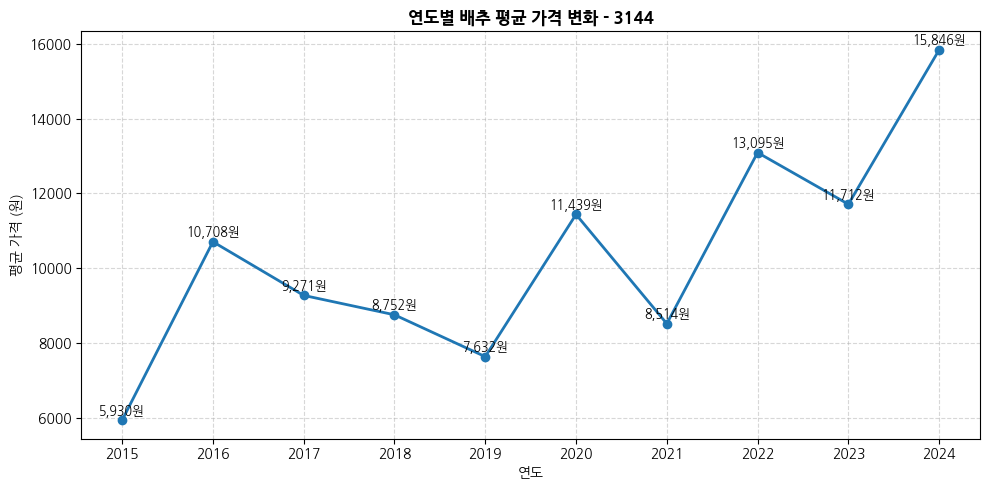

In [34]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib
import matplotlib.pyplot as plt

yearly_avg = df.groupby('year')['exmn_dd_prc'].mean()

plt.figure(figsize=(10, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker='o', color='tab:blue', linewidth=2)
plt.title("연도별 배추 평균 가격 변화 - 3144", fontsize=12, fontweight='bold')
plt.xlabel("연도")
plt.ylabel("평균 가격 (원)")
plt.xticks(yearly_avg.index)
plt.grid(True, linestyle='--', alpha=0.5)

for year, price in yearly_avg.items():
    plt.text(year, price + 150, f"{price:,.0f}원", ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("연도별_배추_평균_가격_변화_3144.png")
plt.show()

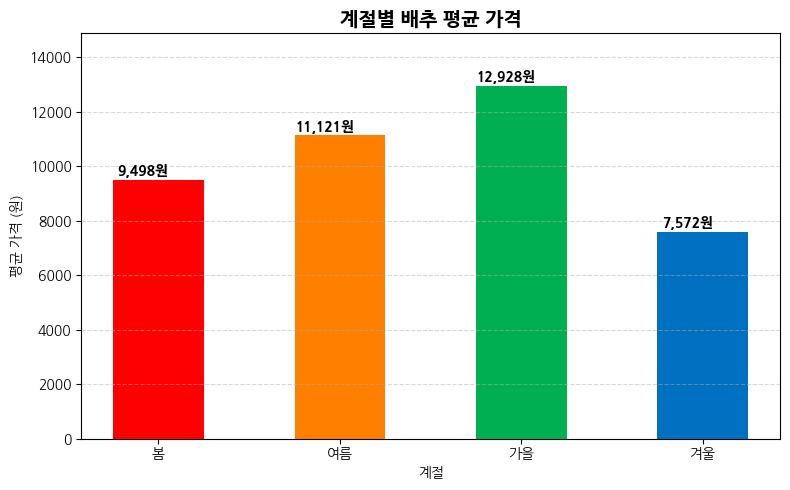

In [37]:
season_order = ['봄', '여름', '가을', '겨울']
seasonal_avg = df.groupby('season')['exmn_dd_prc'].mean().reindex(season_order)

plt.figure(figsize=(8, 5))
bars = plt.bar(seasonal_avg.index, seasonal_avg.values, color=['#FF0000', '#FF7F00', '#00B050', '#0070C0'], width=0.5)
plt.title("계절별 배추 평균 가격", fontsize=14, fontweight='bold')
plt.xlabel("계절")
plt.ylabel("평균 가격 (원)")
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 3.0, height + 70, f"{height:,.0f}원", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, seasonal_avg.max() * 1.15)
plt.tight_layout()
plt.savefig("계절별_배추_평균_가격.png")
plt.show()